# Food Price Watch: Exploratory Data Analysis & Regional Trends
## Comparative Analysis of Food Consumer Price Index Trends Across Philippine Regions, 2020–2026

This notebook executes the entire pipeline: loading raw PSA data, filtering specifically for food-related commodity groups and the 2020–2026 timeframe, reshaping into long format, and generating clean regional visualizations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Global configuration and plot aesthetics
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

sns.set_theme(style='whitegrid', palette='deep', font_scale=1.0)
plt.rcParams['figure.figsize'] = (12, 6)

print('Libraries loaded successfully.')

Libraries loaded successfully.


## Step 1: Load, Filter, and Clean Raw Data (Food Focus: 2020–2026)

In [2]:
# Load the raw dataset (skipping title row)
# Make sure your raw file is named 'cpi_raw.csv' or update path accordingly
DATA_PATH = 'Year-on-Year Changes of the Consumer Price Index in Percent by Commodity Group (2018=100)- January 2019 - September 2026 (1).csv'
raw = pd.read_csv(DATA_PATH, skiprows=1, dtype=str, keep_default_na=False)

# Identify ID vs monthly columns
id_vars = ['Geolocation', 'Commodity Description']
month_cols = [c for c in raw.columns if c not in id_vars]

# Melt wide table to long format
long_df = raw.melt(id_vars=id_vars, value_vars=month_cols, 
                   var_name='period_raw', value_name='raw_value')

# Parse Year and Month fields
long_df['year'] = long_df['period_raw'].str.extract(r'^(\d{4})')[0].astype(int)
long_df['month'] = long_df['period_raw'].str.replace(r'^\d{4}\s*', '', regex=True).str.strip()

# Clean numerical values (replace '..' suppressed data with NaN)
long_df['clean_value'] = long_df['raw_value'].replace(['..', '', 'NA'], np.nan)
long_df['yoy_change'] = pd.to_numeric(long_df['clean_value'], errors='coerce')

# --- SCOPE FILTERING ---
# 1. Restrict years to 2020–2026 as per your title
# 2. Restrict commodities to Food and Non-Alcoholic Beverages / Food subgroups
food_filter = long_df['Commodity Description'].str.contains('FOOD|Food|01 -', case=False, na=False)
year_filter = (long_df['year'] >= 2020) & (long_df['year'] <= 2026)

clean_long = long_df[food_filter & year_filter].dropna(subset=['yoy_change'])[[
    'Geolocation', 'Commodity Description', 'year', 'month', 'yoy_change'
]].sort_values(['Geolocation', 'Commodity Description', 'year', 'month']).reset_index(drop=True)

print(f'Filtered Food dataset shape: {clean_long.shape[0]:,} rows × {clean_long.shape[1]} columns')
display(clean_long.head())

Filtered Food dataset shape: 119,451 rows × 5 columns


,Geolocation,Commodity Description,year,month,yoy_change
0,....Abra,01 - FOOD AND NON-ALCOHOLIC BEVERAGES,2020,Apr,3.3
1,....Abra,01 - FOOD AND NON-ALCOHOLIC BEVERAGES,2020,Aug,2.6
2,....Abra,01 - FOOD AND NON-ALCOHOLIC BEVERAGES,2020,Ave,1.9
3,....Abra,01 - FOOD AND NON-ALCOHOLIC BEVERAGES,2020,Dec,2.7
4,....Abra,01 - FOOD AND NON-ALCOHOLIC BEVERAGES,2020,Feb,-0.5


## Step 2: Time-Series Line Graph (National Food Inflation Trend, 2020–2026)

C:\Users\Dell\AppData\Local\Temp\ipykernel_14736\2698762428.py:21: UserWarning: 'set_params()' not defined for locator of type <class 'matplotlib.category.StrCategoryLocator'>
  plt.locator_params(axis='x', nbins=14)


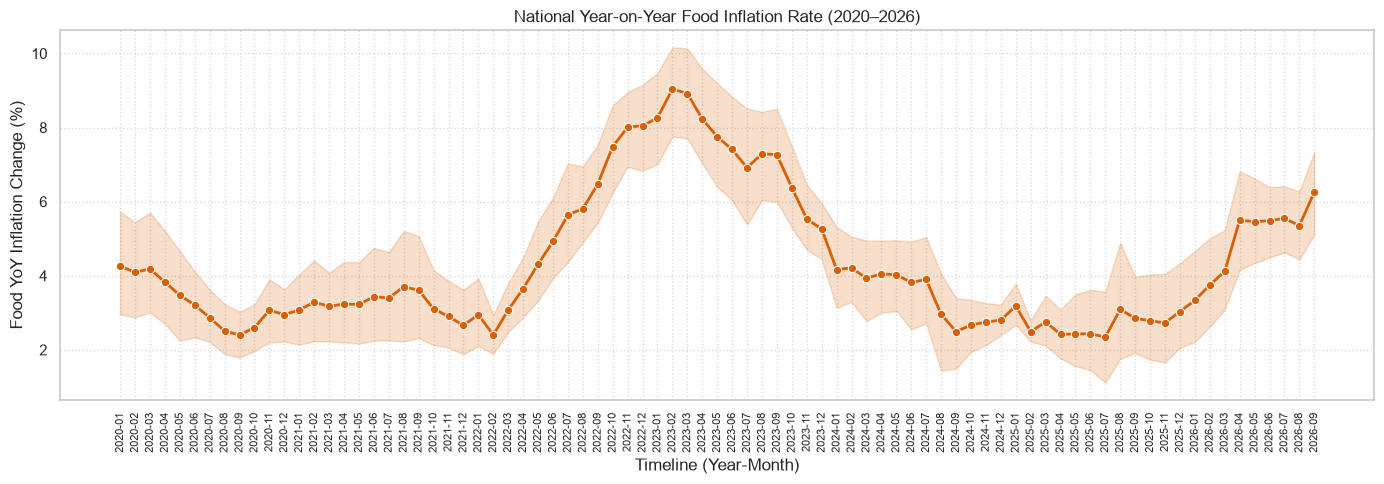

In [3]:

national_food = clean_long[
    (clean_long['Geolocation'] == 'PHILIPPINES') & 
    (clean_long['Commodity Description'].str.contains('FOOD AND NON-ALCOHOLIC BEVERAGES|FOOD', case=False, na=False)) & 
    (~clean_long['month'].str.contains('Ave', na=False))
].copy()

# Sort chronologically
month_mapping = {'Jan':1, 'Feb':2, 'Mar':3, 'Apr':4, 'May':5, 'Jun':6, 
                 'Jul':7, 'Aug':8, 'Sep':9, 'Oct':10, 'Nov':11, 'Dec':12}
national_food['m_num'] = national_food['month'].map(month_mapping)
national_food = national_food.sort_values(['year', 'm_num']).reset_index(drop=True)
national_food['period'] = national_food['year'].astype(str) + '-' + national_food['m_num'].astype(str).str.zfill(2)

# Plot Time-Series Line Chart
fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=national_food, x='period', y='yoy_change', color='#d95f02', linewidth=2, marker='o', ax=ax)
ax.set_title('National Year-on-Year Food Inflation Rate (2020–2026)')
ax.set_xlabel('Timeline (Year-Month)')
ax.set_ylabel('Food YoY Inflation Change (%)')
plt.xticks(rotation=90, fontsize=8)
plt.locator_params(axis='x', nbins=14)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

## Step 3: Regional Food Price Comparison Bar Chart


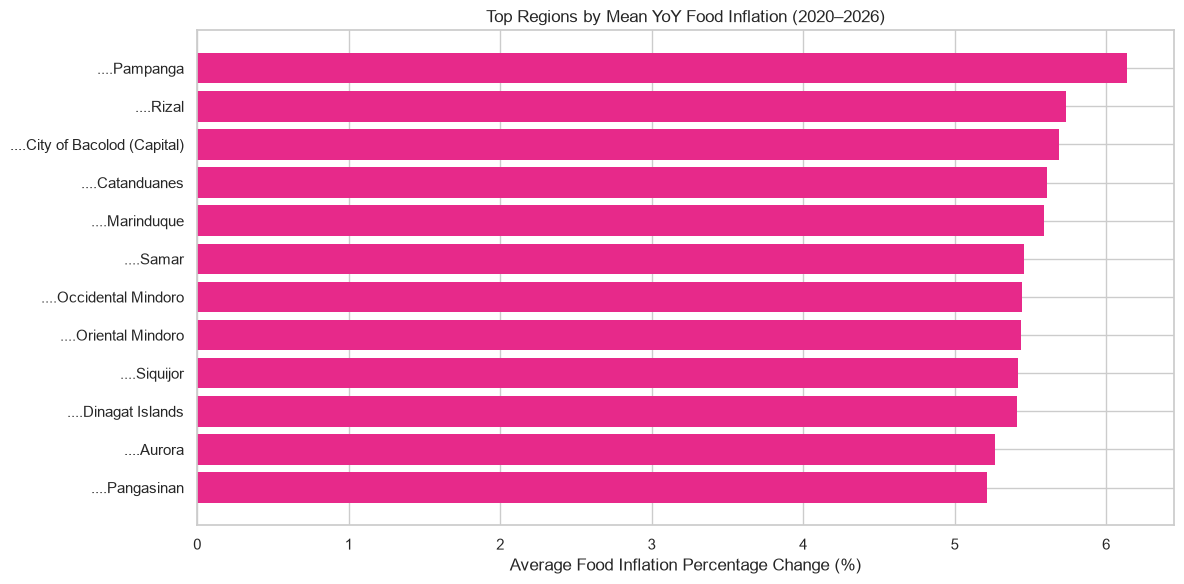

In [4]:
# Compare average food inflation across top regions (excluding the national aggregate row)
regional_food = clean_long[
    (clean_long['Geolocation'] != 'PHILIPPINES') & 
    (~clean_long['Geolocation'].str.contains('Province|District', case=False, na=False))
]

region_grouped = (
    regional_food.groupby('Geolocation')['yoy_change']
    .mean()
    .reset_index()
    .sort_values(by='yoy_change', ascending=False)
    .head(12)  # Top 12 regions to keep the chart clean and readable
    .sort_values(by='yoy_change', ascending=True)
)

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(region_grouped['Geolocation'], region_grouped['yoy_change'], color='#e7298a', edgecolor='none')
ax.set_title('Top Regions by Mean YoY Food Inflation (2020–2026)')
ax.set_xlabel('Average Food Inflation Percentage Change (%)')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

## Step 4: Temporal Food Inflation Heatmap


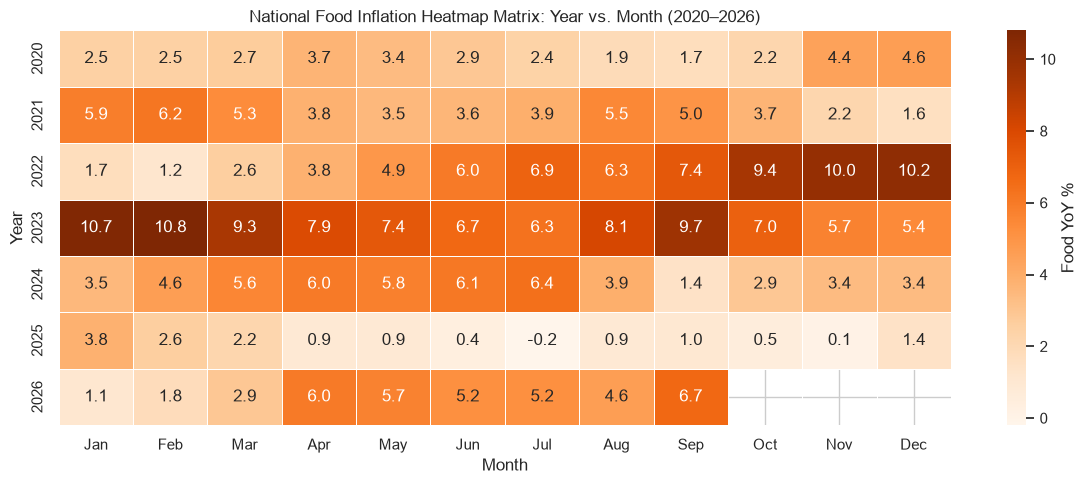

In [5]:
# Filter strictly for the top-level national food aggregate to avoid duplicate rows for the heatmap. Pivot table now has unique year-month entries
heatmap_df = clean_long[
    (clean_long['Geolocation'] == 'PHILIPPINES') & 
    (clean_long['Commodity Description'] == '01 - FOOD AND NON-ALCOHOLIC BEVERAGES') & 
    (~clean_long['month'].str.contains('Ave', na=False))
].copy()

months_list = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
heatmap_df['month'] = pd.Categorical(heatmap_df['month'], categories=months_list, ordered=True)

# Pivot table now has unique year-month entries
pivot_table = heatmap_df.pivot(index='year', columns='month', values='yoy_change')

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(pivot_table, annot=True, fmt='.1f', cmap='Oranges', linewidths=0.4, cbar_kws={'label': 'Food YoY %'}, ax=ax)
ax.set_title('National Food Inflation Heatmap Matrix: Year vs. Month (2020–2026)')
ax.set_xlabel('Month')
ax.set_ylabel('Year')
plt.tight_layout()
plt.show()

# ==========================================
# STEP 5: Export Cleaned Dataset to CSV
# ==========================================

In [6]:
import pandas as pd
import glob

# 1. Automatically locate your raw multi-year CSV file in your working directory
raw_files = glob.glob('*.csv')
# Look for the raw file (exclude the output 'cleaned dataset.csv')
raw_candidates = [f for f in raw_files if f != 'cleaned dataset.csv']

if not raw_candidates:
    raise FileNotFoundError("Please ensure your raw multi-year dataset CSV file is uploaded in the directory.")

DATA_PATH = raw_candidates[0]
print(f"Loading raw dataset from: {DATA_PATH}")

# 2. Read raw dataset (skip title row if present)
raw_df = pd.read_csv(DATA_PATH, skiprows=1, dtype=str, keep_default_na=False)

# 3. Filter for Food commodities only
food_mask = raw_df['Commodity Description'].str.contains('FOOD|Food|01 -', case=False, na=False)

# 4. Select Geolocation, Commodity Description, and all month/year columns from 2020 to 2026
years_str = [str(y) for y in range(2020, 2027)]
target_cols = ['Geolocation', 'Commodity Description'] + [c for c in raw_df.columns if any(c.startswith(y) for y in years_str)]

# Filter and create the full wide dataset (no row caps, keeping all regions, provinces, and cities)
cleaned_wide = raw_df.loc[food_mask, target_cols].copy()

# 5. Export directly to 'cleaned dataset.csv'
OUTPUT_PATH = 'cleaned dataset.csv'
cleaned_wide.to_csv(OUTPUT_PATH, index=False)

print(f"Step 5 Complete: Successfully generated '{OUTPUT_PATH}' with {cleaned_wide.shape[0]:,} rows and {cleaned_wide.shape[1]} columns covering 2020–2026.")
display(cleaned_wide.head())

Loading raw dataset from: Year-on-Year Changes of the Consumer Price Index in Percent by Commodity Group (2018=100)- January 2019 - September 2026 (1).csv
Step 5 Complete: Successfully generated 'cleaned dataset.csv' with 1,440 rows and 93 columns covering 2020–2026.


,Geolocation,Commodity Description,2020 Jan,2020 Feb,2020 Mar,2020 Apr,2020 May,2020 Jun,2020 Jul,2020 Aug,2020 Sep,2020 Oct,2020 Nov,2020 Dec,2020 Ave,...,2025 Dec,2025 Ave,2026 Jan,2026 Feb,2026 Mar,2026 Apr,2026 May,2026 Jun,2026 Jul,2026 Aug,2026 Sep,2026 Oct,2026 Nov,2026 Dec,2026 Ave
1,PHILIPPINES,01 - FOOD AND NON-ALCOHOLIC BEVERAGES,2.5,2.5,2.7,3.7,3.4,2.9,2.4,1.9,1.7,2.2,4.4,4.6,2.9,...,1.4,1.2,1.1,1.8,2.9,6.0,5.7,5.2,5.2,4.6,6.7,..,..,..,..
2,PHILIPPINES,01.1 - FOOD,2.5,2.3,2.7,3.8,3.4,2.9,2.5,1.9,1.7,2.2,4.6,4.9,2.9,...,1.2,1.0,0.7,1.6,2.7,6.1,5.8,5.3,5.3,4.6,6.8,..,..,..,..
18,PHILIPPINES,01.1.3 - Fish and other seafood (ND),8.9,8.6,10.5,9.5,8.1,6.2,4.4,2.8,3.0,4.2,5.4,2.6,6.2,...,9.0,6.4,7.3,7.7,6.6,9.4,8.8,7.8,7.8,6.6,7.4,..,..,..,..
22,PHILIPPINES,"01.1.3.4 - Other seafood, live, fresh, chilled...",8.5,7.1,6.8,3.8,3.3,3.1,1.7,1.8,1.2,2.3,3.5,4.3,4.0,...,5.3,5.3,2.2,5.2,6.2,7.5,6.8,6.0,6.4,6.0,8.0,..,..,..,..
23,PHILIPPINES,01.1.3.6 - Other seafood preparations (ND),7.0,6.7,6.0,5.5,5.0,4.8,4.5,3.4,2.9,2.6,2.8,3.0,4.5,...,1.7,1.7,1.6,1.6,1.6,2.7,4.1,6.4,7.0,7.2,8.9,..,..,..,..
